In [30]:
from lib import *
from sklearn.model_selection import StratifiedGroupKFold
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

# for S00 only (5 folds)

In [2]:
_, S00_exams_indices, N_S00_exams  = load_s00_conn_memmap()

In [3]:
meta = read_metadata()
labels = np.asarray(meta['pathology']).astype(int)[:N_S00_exams]
patients = np.asarray(meta['patient_id'])[:N_S00_exams]
sex = np.asarray(meta['female']).astype(int)[:N_S00_exams]
age = np.asarray(meta['age_group'])[:N_S00_exams]

Initiate the splitter

In [4]:
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=0)
folds_train_indieces, folds_val_indieces, folds_test_indieces = [], [], []

Perform the train-val-test split

In [5]:
for i, (train_index, test_index) in enumerate(sgkf.split(X=S00_exams_indices, y=labels, groups=patients)):
    y_tr, g_tr = labels[train_index], patients[train_index]
    inner = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=i)
    training, validation = next(iter(inner.split(np.zeros(len(train_index)), y_tr, g_tr)))

    folds_train_indieces.append(train_index[training])
    folds_val_indieces.append(train_index[validation])
    folds_test_indieces.append(test_index)

Check the results

In [6]:
print([(len(a), len(b), len(c)) for a, b, c in zip(folds_train_indieces, folds_val_indieces, folds_test_indieces)])

[(1085, 269, 343), (1090, 270, 337), (1093, 276, 328), (1078, 270, 349), (1091, 266, 340)]


Lekeage check

In [9]:
all_test = np.concatenate(folds_test_indieces)

for k, (tr, va, te) in enumerate(zip(folds_train_indieces, folds_val_indieces, folds_test_indieces)):
    # 1. no exam in two sets
    assert not (set(tr) & set(va)) and not (set(tr) & set(te)) and not (set(va) & set(te)), f"fold {k}: exam overlap"
    # 2. no patient in two sets (the important one)
    p_tr, p_va, p_te = set(patients[tr]), set(patients[va]), set(patients[te])
    assert not (p_tr & p_va), f"fold {k}: patient in train and val"
    assert not (p_tr & p_te), f"fold {k}: patient in train and test"
    assert not (p_va & p_te), f"fold {k}: patient in val and test"
    # 3. the three sets together cover every exam exactly once
    assert len(tr) + len(va) + len(te) == len(S00_exams_indices), f"fold {k}: sizes don't add up"
    # 4. class balance
    print(k, "train", np.bincount(labels[tr]), "val", np.bincount(labels[va]), "test", np.bincount(labels[te]))

# 5. across folds: every exam is tested exactly once
assert len(all_test) == len(set(all_test)) == len(S00_exams_indices), "test folds overlap or miss exams"
print("no leakage in splits")

0 train [567 518] val [147 122] test [163 180]
1 train [542 548] val [148 122] test [187 150]
2 train [569 524] val [129 147] test [179 149]
3 train [550 528] val [146 124] test [181 168]
4 train [563 528] val [147 119] test [167 173]
no leakage in splits


Save to file

In [10]:
np.savez("splits/s00.npz",
         **{f"fold{i}_{name}": arr
            for i, (a, b, c) in enumerate(zip(folds_train_indieces, folds_val_indieces, folds_test_indieces))
            for name, arr in (("train", a), ("val", b), ("test", c))})

Read from file per fold

In [15]:
s = np.load("splits/s00.npz")
k = 1
train_idx, val_idx, test_idx = s[f"fold{k}_train"], s[f"fold{k}_val"], s[f"fold{k}_test"]

# for all (10 folds)

In [34]:
mm, exams_indices  = load_conn_memmap()

In [35]:
exams_indices

array([    0,     1,     2, ..., 34828, 34829, 34830], shape=(34831,))

In [36]:
meta = read_metadata()
labels = np.asarray(meta['pathology']).astype(int)
patients = np.asarray(meta['patient_id'])
sex = np.asarray(meta['female']).astype(int)
age = np.asarray(meta['age_group'])

In [37]:
sites = np.asarray(meta['site'])
sites

array(['S00', 'S00', 'S00', ..., 'S29', 'S29', 'S29'],
      shape=(34831,), dtype=object)

Initiate the splitter with sites as groups (each patient is exclusively in only one site)

In [38]:
sgkf = StratifiedGroupKFold(n_splits=10, shuffle=True, random_state=42)
folds_train_indieces, folds_val_indieces, folds_test_indieces = [], [], []

In [39]:
for i, (train_index, test_index) in enumerate(sgkf.split(exams_indices, y=labels, groups=sites)):
    y_tr, g_tr = labels[train_index], sites[train_index]   # sites instead of patients
    training, validation = next(iter(sgkf.split(np.zeros(len(train_index)), y_tr, g_tr)))

    folds_train_indieces.append(train_index[training])
    folds_val_indieces.append(train_index[validation])
    folds_test_indieces.append(test_index)

### Let's evaluate the split

In [40]:
print([(len(a), len(b), len(c)) for a, b, c in zip(folds_train_indieces, folds_val_indieces, folds_test_indieces)])

[(32713, 1147, 971), (32161, 1260, 1410), (30190, 2526, 2115), (29870, 2093, 2868), (29703, 1958, 3170), (25827, 418, 8586), (28532, 1888, 4411), (32242, 1136, 1453), (27077, 1641, 6113), (29787, 1310, 3734)]


In [41]:
splits = list(zip(folds_train_indieces, folds_val_indieces, folds_test_indieces))
names = ["train", "val", "test"]
site_ids = np.unique(sites)

Leakage checks

In [42]:
for i, parts in enumerate(splits):
    for a in range(3):
        for b in range(a + 1, 3):
            for level, arr in [("exam", np.arange(len(sites))), ("patient", patients), ("site", sites)]:
                shared = set(arr[parts[a]]) & set(arr[parts[b]])
                assert not shared, f"fold {i}: {level} leak {names[a]}/{names[b]}: {sorted(shared)[:5]}"
    assert len(set().union(*map(set, parts))) == sum(map(len, parts)), f"fold {i}: duplicates"

all_test = np.concatenate([p[2] for p in splits])
assert len(all_test) == len(set(all_test)), "exam appears in test of multiple folds"
print("No leakage found")

No leakage found


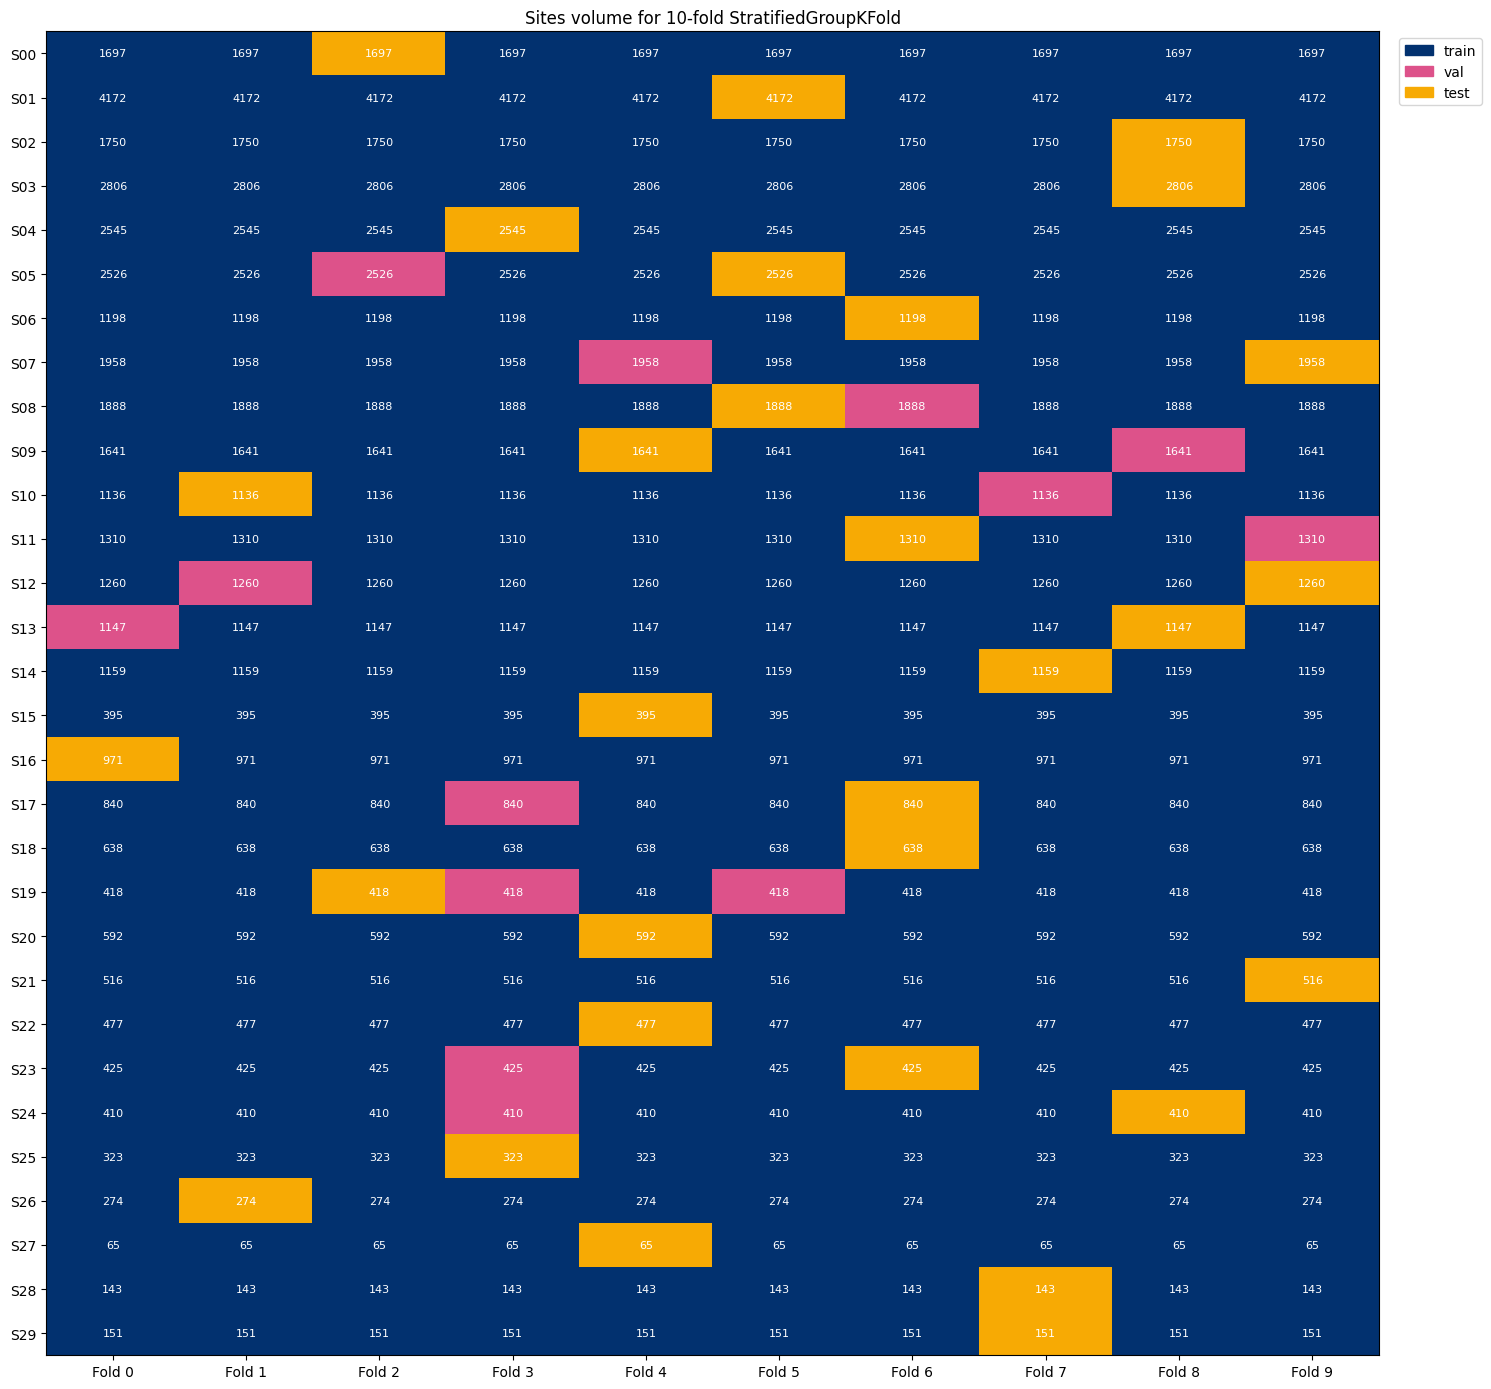

In [54]:
role = np.full((len(site_ids), len(splits)), -1)       
count = np.zeros_like(role)
for f, parts in enumerate(splits):
    for r, idx in enumerate(parts):
        for s, n in zip(*np.unique(sites[idx], return_counts=True)):
            role[np.where(site_ids == s)[0][0], f] = r
            count[np.where(site_ids == s)[0][0], f] = n

colors = ["#dddddd", "#02316F", "#DD528A", "#F7AA04"]  
fig, ax = plt.subplots(figsize=(1.2 * len(splits) + 3, 0.4 * len(site_ids) + 2))
ax.imshow(role + 1, cmap=ListedColormap(colors), vmin=0, vmax=3, aspect="auto")

for r in range(role.shape[0]):
    for f in range(role.shape[1]):
        if count[r, f]:
            ax.text(f, r, count[r, f], ha="center", va="center", color="white", fontsize=8)

ax.set_xticks(range(len(splits)), [f"Fold {i}" for i in range(len(splits))])
ax.set_yticks(range(len(site_ids)), site_ids)
ax.legend(handles=[Patch(color=c, label=l) for c, l in zip(colors[1:], names)],
          loc="upper left", bbox_to_anchor=(1.01, 1))
ax.set_title("Sites volume for 10-fold StratifiedGroupKFold")
plt.tight_layout()
plt.savefig("plots/fold_site_map.png", dpi=150)
plt.show()

In [44]:
for i, parts in enumerate(splits):
    print(i, {n: np.round(labels[p].mean(), 3) for n, p in zip(names, parts)})

0 {'train': np.float64(0.55), 'val': np.float64(0.816), 'test': np.float64(0.372)}
1 {'train': np.float64(0.561), 'val': np.float64(0.537), 'test': np.float64(0.425)}
2 {'train': np.float64(0.549), 'val': np.float64(0.605), 'test': np.float64(0.566)}
3 {'train': np.float64(0.534), 'val': np.float64(0.424), 'test': np.float64(0.86)}
4 {'train': np.float64(0.583), 'val': np.float64(0.44), 'test': np.float64(0.359)}
5 {'train': np.float64(0.488), 'val': np.float64(0.904), 'test': np.float64(0.738)}
6 {'train': np.float64(0.58), 'val': np.float64(0.796), 'test': np.float64(0.283)}
7 {'train': np.float64(0.547), 'val': np.float64(0.397), 'test': np.float64(0.843)}
8 {'train': np.float64(0.588), 'val': np.float64(0.22), 'test': np.float64(0.496)}
9 {'train': np.float64(0.572), 'val': np.float64(0.438), 'test': np.float64(0.455)}


The label stratification is satisfied in train. Validation and test sets are more prone to class imbalance, cause they rely on one or couple smaller sites. Grouping by sites is more harsh and dominates label startification.

In [45]:
np.savez("splits/all_sites_10_folds.npz",
         **{f"fold{i}_{name}": arr
            for i, (a, b, c) in enumerate(zip(folds_train_indieces, folds_val_indieces, folds_test_indieces))
            for name, arr in (("train", a), ("val", b), ("test", c))})

In [49]:
s = np.load("splits/all_sites_10_folds.npz")
k = 2
train_idx, val_idx, test_idx = s[f"fold{k}_train"], s[f"fold{k}_val"], s[f"fold{k}_test"]